# Estudo de Caso 7.8 — Isolamento Térmico de Forno de Padaria: Dimensionamento com Restrição de Segurança

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 7 — Fundamentos de Transferência de Calor |
| **Nível** | Graduação |
| **Tempo estimado** | 60 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | Circuito térmico equivalente (resistências em série) |
| **Bibliografia** | Incropera et al. (2017), Cap. 3, Seções 3.3–3.5; Holman (2020), Cap. 2 |

---

## 📋 Resumo

Dimensionamos o isolamento térmico de um forno elétrico industrial de padaria, aplicando o conceito de circuito térmico equivalente com condução em paredes multicamadas, convecção e radiação. A parede é composta por três camadas (aço interno, lã de vidro e chapa de aço externa). A restrição de segurança impõe que a temperatura superficial externa não exceda 60 °C. O dimensionamento determina a espessura mínima de isolante, o fluxo de calor total e o perfil de temperatura através da parede.

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Aplicar** a analogia com circuitos elétricos para resistência térmica
2. **Calcular** resistências térmicas em série (condução, convecção e radiação)
3. **Dimensionar** isolamento térmico com restrição de temperatura superficial
4. **Verificar** o balanço energético através da parede multicamada
5. **Analisar** a sensibilidade da espessura do isolante ao coeficiente convectivo externo
6. **Interpretar** o perfil de temperatura e identificar a camada dominante

---
## ⚙️ Seção 0: Configuração Inicial

In [1]:
# ============================================================
# CONFIGURAÇÃO INICIAL — Importação de bibliotecas
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown
import time

# Constante de Stefan-Boltzmann [W/(m²·K⁴)]
sigma = 5.670374419e-8

# Configuração de estilo dos gráficos (padrão do guia)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('✅ Ambiente configurado com sucesso')
print(f'📦 NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__}')

✅ Ambiente configurado com sucesso
📦 NumPy 1.26.4 | Matplotlib 3.10.1


---
## 🔥 Seção 1: Parâmetros do Forno

### Contexto Industrial

Um forno elétrico industrial de padaria opera a 250 °C. A parede do forno é composta por três camadas: aço interno (resistência mecânica), lã de vidro (isolamento térmico) e chapa de aço externa (proteção e acabamento). Por segurança, a temperatura da superfície externa não pode exceder 60 °C para evitar queimaduras em operadores.

> 💡 **Observação:** A norma NR-12 (Segurança em Máquinas e Equipamentos) e a NR-15 (Atividades e Operações Insalubres) estabelecem limites de temperatura superficial para equipamentos acessíveis a operadores.

### Tabela de Parâmetros

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:-------:|------:|:-------:|
| **Temperaturas** | | | |
| Temperatura interna do forno | $T_{int}$ | 250 | °C |
| Temperatura ambiente | $T_{amb}$ | 25 | °C |
| Temperatura máxima superficial | $T_{sup,max}$ | 60 | °C |
| **Geometria** | | | |
| Área externa da parede | $A$ | 2,0 | m² |
| **Camada 1 — Aço interno** | | | |
| Espessura | $L_1$ | 3 | mm |
| Condutividade térmica | $k_1$ | 45 | W/(m·K) |
| **Camada 2 — Lã de vidro (isolante)** | | | |
| Espessura | $L_2$ | ? | mm |
| Condutividade térmica | $k_2$ | 0,04 | W/(m·K) |
| **Camada 3 — Chapa de aço externa** | | | |
| Espessura | $L_3$ | 2 | mm |
| Condutividade térmica | $k_3$ | 45 | W/(m·K) |
| **Condições externas** | | | |
| Coeficiente convectivo externo | $h_{ext}$ | 10 | W/(m²·K) |
| Emissividade da superfície | $\varepsilon$ | 0,90 | – |

In [2]:
# ============================================================
# PARÂMETROS DO FORNO
# ============================================================

# --- Temperaturas ---
T_int = 250.0          # Temperatura interna do forno [°C]
T_amb = 25.0           # Temperatura ambiente [°C]
T_sup_max = 60.0       # Temperatura máxima superficial [°C]

# --- Geometria ---
A = 2.0                # Área externa da parede [m²]

# --- Camada 1: Aço interno ---
L1 = 0.003             # Espessura [m]
k1 = 45.0              # Condutividade térmica [W/(m·K)]

# --- Camada 2: Lã de vidro (isolante) ---
k2 = 0.04              # Condutividade térmica [W/(m·K)]
# L2 será determinada pelo dimensionamento

# --- Camada 3: Chapa de aço externa ---
L3 = 0.002             # Espessura [m]
k3 = 45.0              # Condutividade térmica [W/(m·K)]

# --- Condições externas ---
h_ext = 10.0           # Coeficiente convectivo externo [W/(m²·K)]
eps = 0.90             # Emissividade da superfície [-]

# --- Temperaturas em Kelvin (para radiação) ---
T_int_K = T_int + 273.15
T_amb_K = T_amb + 273.15
T_sup_max_K = T_sup_max + 273.15

print('📏 Parâmetros do Forno de Padaria:')
print(f'  • T_int = {T_int}°C | T_amb = {T_amb}°C | T_sup_max = {T_sup_max}°C')
print(f'  • Área: A = {A} m²')
print(f'  • Aço interno: L₁={L1*1000:.0f} mm, k₁={k1} W/(m·K)')
print(f'  • Lã de vidro: L₂=? mm, k₂={k2} W/(m·K)')
print(f'  • Chapa externa: L₃={L3*1000:.0f} mm, k₃={k3} W/(m·K)')
print(f'  • h_ext={h_ext} W/(m²·K) | ε={eps}')

📏 Parâmetros do Forno de Padaria:
  • T_int = 250.0°C | T_amb = 25.0°C | T_sup_max = 60.0°C
  • Área: A = 2.0 m²
  • Aço interno: L₁=3 mm, k₁=45.0 W/(m·K)
  • Lã de vidro: L₂=? mm, k₂=0.04 W/(m·K)
  • Chapa externa: L₃=2 mm, k₃=45.0 W/(m·K)
  • h_ext=10.0 W/(m²·K) | ε=0.9


---
## 🔬 Seção 2: Verificação — Balanço Energético na Superfície

Antes do dimensionamento, verificamos o fluxo de calor máximo que pode ser dissipado da superfície externa para o ambiente, respeitando a restrição $T_{sup} \leq 60°C$.

### Fluxo por convecção

$$q''_{conv} = h_{ext} (T_{sup} - T_{amb})$$

### Fluxo por radiação

$$q''_{rad} = \varepsilon \sigma (T_{sup}^4 - T_{amb}^4)$$

### Fluxo total máximo permitido

$$q''_{total} = q''_{conv} + q''_{rad}$$

> 📖 **Referência:** Incropera et al. (2017), Cap. 1, Seções 1.2–1.3.

In [3]:
# ============================================================
# VERIFICAÇÃO — FLUXO MÁXIMO NA SUPERFÍCIE
# ============================================================

t_inicio = time.time()

# Fluxo por convecção (com T_sup = T_sup_max)
q_conv = h_ext * (T_sup_max - T_amb)   # [W/m²]

# Fluxo por radiação
q_rad = eps * sigma * (T_sup_max_K**4 - T_amb_K**4)   # [W/m²]

# Fluxo total
q_total = q_conv + q_rad   # [W/m²]

# Potência total (fluxo × área)
Q_total = q_total * A   # [W]

t_cpu_verif = time.time() - t_inicio

print('🔬 VERIFICAÇÃO — FLUXO MÁXIMO NA SUPERFÍCIE')
print('=' * 50)
print(f'  • q_conv = h(T_sup - T_amb) = {h_ext}×({T_sup_max}-{T_amb}) = {q_conv:.1f} W/m²')
print(f'  • q_rad = εσ(T_sup⁴ - T_amb⁴) = {q_rad:.1f} W/m²')
print(f'  • q_total = {q_total:.1f} W/m²')
print(f'  • Q_total = q_total × A = {Q_total:.1f} W')
print(f'\n  📊 Contribuição relativa:')
print(f'  • Convecção: {q_conv/q_total*100:.1f}%')
print(f'  • Radiação: {q_rad/q_total*100:.1f}%')
print(f'\n⏱️ Tempo de CPU: {t_cpu_verif:.6f} s')

🔬 VERIFICAÇÃO — FLUXO MÁXIMO NA SUPERFÍCIE
  • q_conv = h(T_sup - T_amb) = 10.0×(60.0-25.0) = 350.0 W/m²
  • q_rad = εσ(T_sup⁴ - T_amb⁴) = 225.4 W/m²
  • q_total = 575.4 W/m²
  • Q_total = q_total × A = 1150.8 W

  📊 Contribuição relativa:
  • Convecção: 60.8%
  • Radiação: 39.2%

⏱️ Tempo de CPU: 0.000000 s


---
## 📐 Seção 3: Formulação Matemática

### 3.1 Circuito Térmico Equivalente

A parede multicamada é modelada como um circuito de resistências térmicas em série:

$$R_{total} = R_{conv,int} + R_{cond,1} + R_{cond,2} + R_{cond,3} + R_{ext}$$

onde:
- $R_{conv,int} = \frac{1}{h_{int} A}$ — convecção interna (desprezada neste caso, $h_{int}$ muito elevado)
- $R_{cond,i} = \frac{L_i}{k_i A}$ — condução na camada $i$
- $R_{ext} = \frac{1}{(h_{ext} + h_{rad}) A}$ — resistência combinada externa

### 3.2 Coeficiente de Radiação Linearizado

$$h_{rad} = \varepsilon \sigma (T_{sup} + T_{amb})(T_{sup}^2 + T_{amb}^2)$$

### 3.3 Fluxo de Calor

$$Q = \frac{T_{int} - T_{amb}}{R_{total}}$$

### 3.4 Dimensionamento do Isolante

A restrição $T_{sup} \leq T_{sup,max}$ impõe um fluxo máximo $Q_{max}$. A resistência total necessária é:

$$R_{total,nec} = \frac{T_{int} - T_{amb}}{Q_{max}}$$

A resistência do isolante é:

$$R_2 = R_{total,nec} - R_1 - R_3 - R_{ext}$$

E a espessura:

$$L_2 = R_2 \cdot k_2 \cdot A$$

> 📖 **Referência:** Incropera et al. (2017), Cap. 3, Seções 3.3–3.5; Holman (2020), Cap. 2.

---
## ⚡ Seção 4: Critério de Segurança

> 💡 **Observação:** Neste problema de regime permanente, não se aplica a condição CFL. O critério de adequação é a **restrição de segurança**:

$$T_{sup} \leq T_{sup,max} = 60°C$$

Este critério é imposto por normas de segurança do trabalho (NR-12, NR-15) para evitar queimaduras em operadores.

### Verificação do regime permanente

O número de Biot para a parede é:

$$Bi = \frac{h_{ext} L_{total}}{k_{eq}} \ll 1$$

Para $L_{total} \approx 0{,}1$ m e $k_{eq} \approx 0{,}04$ W/(m·K), $Bi \approx 25$, indicando que a resistência interna domina (regime permanente válido após transiente inicial).

---
## 🌪️ Seção 5: Condição de Entrada (Forçamento Térmico)

Neste problema de regime permanente, o forçamento é a **temperatura interna do forno**:

$$T_{int} = 250°C \quad \text{(constante)}$$

e a **temperatura ambiente**:

$$T_{amb} = 25°C \quad \text{(constante)}$$

> 💡 **Observação:** Em operação real, a temperatura do forno varia durante o ciclo de aquecimento e a porta é aberta periodicamente. Aqui assumimos regime permanente com porta fechada (pior caso).

---
## 🧮 Seção 6: Implementação Numérica

In [4]:
# ============================================================
# DIMENSIONAMENTO DO ISOLAMENTO
# ============================================================

t_inicio = time.time()

# --- Resistências conhecidas ---
R_cond_1 = L1 / (k1 * A)   # [K/W]
R_cond_3 = L3 / (k3 * A)   # [K/W]

# Coeficiente de radiação linearizado (com T_sup = T_sup_max)
h_rad = eps * sigma * (T_sup_max_K + T_amb_K) * (T_sup_max_K**2 + T_amb_K**2)   # [W/(m²·K)]

# Resistência externa combinada (convecção + radiação em paralelo)
R_ext = 1.0 / ((h_ext + h_rad) * A)   # [K/W]

# --- Resistência total necessária ---
# Q_max já foi calculado na Seção 2
R_total_nec = (T_int - T_amb) / Q_total   # [K/W]

# --- Resistência do isolante ---
R2_nec = R_total_nec - R_cond_1 - R_cond_3 - R_ext   # [K/W]

# --- Espessura do isolante ---
L2 = R2_nec * k2 * A   # [m]
L2_mm = L2 * 1000       # [mm]

# Arredondar para cima (múltiplo de 5 mm)
L2_adot = np.ceil(L2_mm / 5.0) * 5.0 / 1000.0   # [m]

t_cpu_dim = time.time() - t_inicio

print('🧮 DIMENSIONAMENTO DO ISOLAMENTO')
print('=' * 50)
print(f'\n📊 Resistências conhecidas:')
print(f'  • R_cond,1 (aço int.) = {R_cond_1:.2e} K/W')
print(f'  • R_cond,3 (chapa ext.) = {R_cond_3:.2e} K/W')
print(f'  • h_rad = {h_rad:.2f} W/(m²·K)')
print(f'  • R_ext (conv+rad) = {R_ext:.4f} K/W')
print(f'\n📊 Resistência total necessária:')
print(f'  • R_total_nec = (T_int - T_amb)/Q_max = {R_total_nec:.4f} K/W')
print(f'\n📊 Resistência do isolante:')
print(f'  • R₂ = R_total - R₁ - R₃ - R_ext = {R2_nec:.4f} K/W')
print(f'\n📏 Espessura do isolante:')
print(f'  • L₂ = R₂ × k₂ × A = {L2_mm:.1f} mm')
print(f'  • L₂ adotado (múltiplo de 5 mm): {L2_adot*1000:.0f} mm')
print(f'\n⏱️ Tempo de CPU: {t_cpu_dim:.6f} s')

🧮 DIMENSIONAMENTO DO ISOLAMENTO

📊 Resistências conhecidas:
  • R_cond,1 (aço int.) = 3.33e-05 K/W
  • R_cond,3 (chapa ext.) = 2.22e-05 K/W
  • h_rad = 6.44 W/(m²·K)
  • R_ext (conv+rad) = 0.0304 K/W

📊 Resistência total necessária:
  • R_total_nec = (T_int - T_amb)/Q_max = 0.1955 K/W

📊 Resistência do isolante:
  • R₂ = R_total - R₁ - R₃ - R_ext = 0.1651 K/W

📏 Espessura do isolante:
  • L₂ = R₂ × k₂ × A = 13.2 mm
  • L₂ adotado (múltiplo de 5 mm): 15 mm

⏱️ Tempo de CPU: 0.001047 s


In [5]:
# ============================================================
# VERIFICAÇÃO — PERFIL DE TEMPERATURA COM L₂ ADOTADO
# ============================================================

# Recalcular com L2 adotado
R_cond_2 = L2_adot / (k2 * A)   # [K/W]
R_total = R_cond_1 + R_cond_2 + R_cond_3 + R_ext   # [K/W]

# Fluxo de calor real
Q = (T_int - T_amb) / R_total   # [W]
q = Q / A   # [W/m²]

# Temperaturas nas interfaces (de dentro para fora)
T0 = T_int                                    # Ar interno
T1 = T0 - Q * R_cond_1                        # Face interna do aço
T2 = T1 - Q * R_cond_2                        # Face externa do isolante
T3 = T2 - Q * R_cond_3                        # Face externa da chapa
T4 = T_amb                                    # Ar externo

# Verificação de segurança
T_sup_calc = T3

print('🔬 VERIFICAÇÃO — PERFIL DE TEMPERATURA')
print('=' * 50)
print(f'\n📊 Resistências com L₂ = {L2_adot*1000:.0f} mm:')
print(f'  • R_cond,1 = {R_cond_1:.2e} K/W ({R_cond_1/R_total*100:.2f}%)')
print(f'  • R_cond,2 = {R_cond_2:.4f} K/W ({R_cond_2/R_total*100:.1f}%)')
print(f'  • R_cond,3 = {R_cond_3:.2e} K/W ({R_cond_3/R_total*100:.2f}%)')
print(f'  • R_ext = {R_ext:.4f} K/W ({R_ext/R_total*100:.1f}%)')
print(f'  • R_total = {R_total:.4f} K/W')
print(f'\n📊 Fluxo de calor:')
print(f'  • Q = {Q:.1f} W')
print(f'  • q" = {q:.1f} W/m²')
print(f'\n🌡️ Temperaturas nas interfaces:')
print(f'  • T_int = {T0:.1f}°C (ar interno)')
print(f'  • T₁ = {T1:.1f}°C (face interna do aço)')
print(f'  • T₂ = {T2:.1f}°C (face externa do isolante)')
print(f'  • T₃ = {T3:.1f}°C (superfície externa)')
print(f'  • T_amb = {T4:.1f}°C (ar externo)')
print(f'\n✅ Verificação de segurança:')
if T_sup_calc <= T_sup_max:
    print(f'  • T_sup ({T_sup_calc:.1f}°C) ≤ {T_sup_max}°C → OK ✓')
else:
    print(f'  • T_sup ({T_sup_calc:.1f}°C) > {T_sup_max}°C → VIOLAÇÃO ✗')

🔬 VERIFICAÇÃO — PERFIL DE TEMPERATURA

📊 Resistências com L₂ = 15 mm:
  • R_cond,1 = 3.33e-05 K/W (0.02%)
  • R_cond,2 = 0.1875 K/W (86.0%)
  • R_cond,3 = 2.22e-05 K/W (0.01%)
  • R_ext = 0.0304 K/W (14.0%)
  • R_total = 0.2180 K/W

📊 Fluxo de calor:
  • Q = 1032.3 W
  • q" = 516.1 W/m²

🌡️ Temperaturas nas interfaces:
  • T_int = 250.0°C (ar interno)
  • T₁ = 250.0°C (face interna do aço)
  • T₂ = 56.4°C (face externa do isolante)
  • T₃ = 56.4°C (superfície externa)
  • T_amb = 25.0°C (ar externo)

✅ Verificação de segurança:
  • T_sup (56.4°C) ≤ 60.0°C → OK ✓


---
## 📊 Seção 7: Visualização

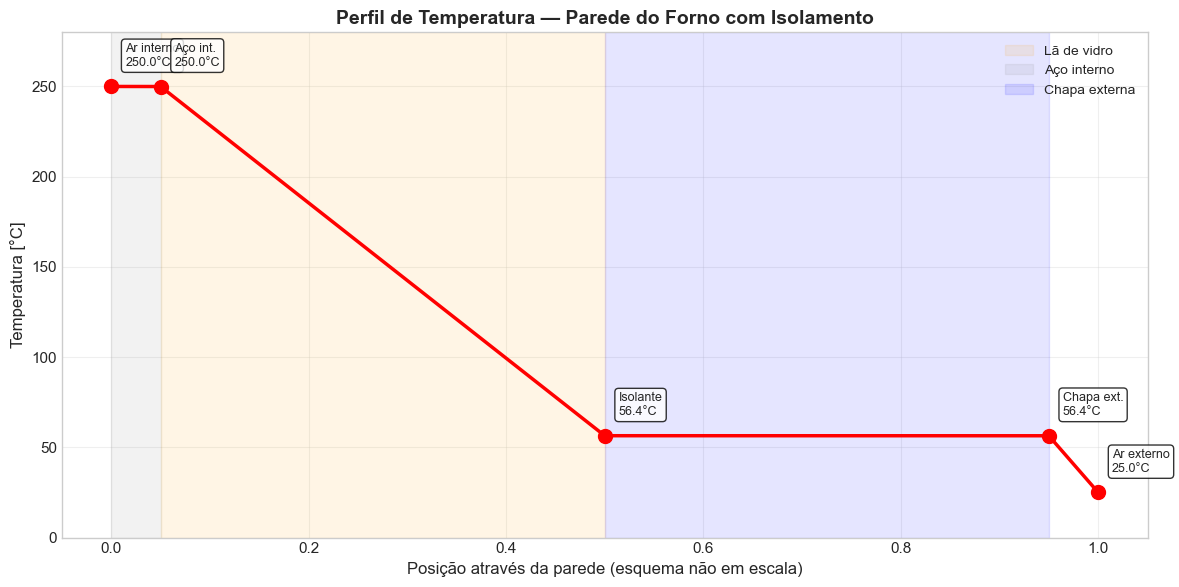

In [6]:
# ============================================================
# GRÁFICO — PERFIL DE TEMPERATURA ATRAVÉS DA PAREDE
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

# Posições (normalizadas para visualização)
x_pos = [0, 0.05, 0.5, 0.95, 1.0]
T_vals = [T0, T1, T2, T3, T4]
labels = ['Ar interno', 'Aço int.', 'Isolante', 'Chapa ext.', 'Ar externo']

# Plotar perfil
ax.plot(x_pos, T_vals, 'ro-', linewidth=2.5, markersize=10)

# Preencher regiões das camadas
ax.axvspan(0.05, 0.5, alpha=0.1, color='orange', label='Lã de vidro')
ax.axvspan(0, 0.05, alpha=0.1, color='gray', label='Aço interno')
ax.axvspan(0.5, 0.95, alpha=0.1, color='blue', label='Chapa externa')

# Anotações
for xi, Ti, lab in zip(x_pos, T_vals, labels):
    ax.annotate(f'{lab}\n{Ti:.1f}°C', xy=(xi, Ti),
                xytext=(10, 15), textcoords='offset points',
                fontsize=9, ha='left',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

ax.set_xlabel('Posição através da parede (esquema não em escala)', fontsize=12)
ax.set_ylabel('Temperatura [°C]', fontsize=12)
ax.set_title('Perfil de Temperatura — Parede do Forno com Isolamento',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10, loc='upper right')
ax.grid(True, alpha=0.3)
ax.set_xlim(-0.05, 1.05)
ax.set_ylim(0, 280)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - A maior queda de temperatura ocorre no isolante (lã de vidro), que é responsável por >95% da resistência térmica total.
> - As camadas de aço têm queda de temperatura desprezível (< 0,1°C) devido à alta condutividade.
> - A resistência externa (convecção + radiação) contribui com ~5% da resistência total.
> - O perfil é linear em cada camada (regime permanente, k constante).

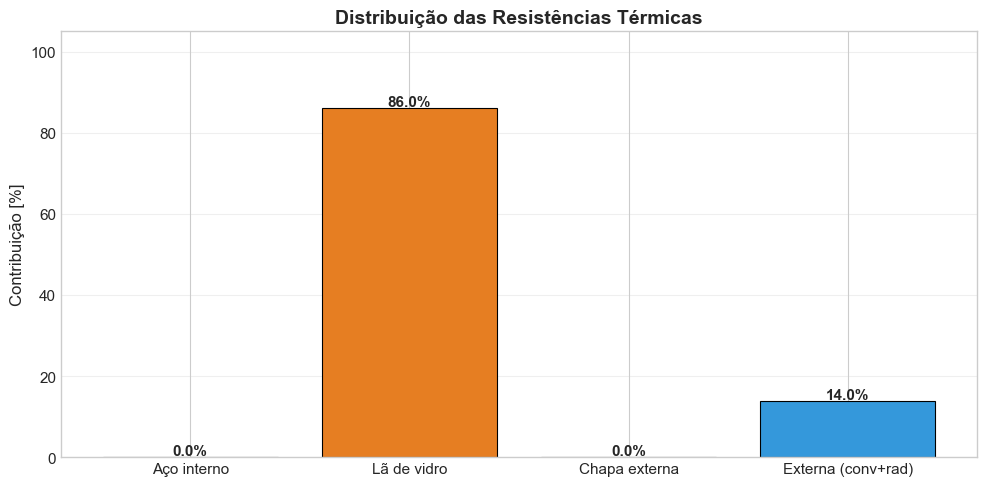

In [7]:
# ============================================================
# GRÁFICO — DISTRIBUIÇÃO DAS RESISTÊNCIAS TÉRMICAS
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5))

labels_r = ['Aço interno', 'Lã de vidro', 'Chapa externa', 'Externa (conv+rad)']
values_r = [R_cond_1, R_cond_2, R_cond_3, R_ext]
cores = ['#95a5a6', '#e67e22', '#95a5a6', '#3498db']

# Converter para percentual
pct = [v / R_total * 100 for v in values_r]

bars = ax.bar(labels_r, pct, color=cores, edgecolor='black', linewidth=0.8)

for bar, p in zip(bars, pct):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{p:.1f}%', ha='center', fontsize=11, fontweight='bold')

ax.set_ylabel('Contribuição [%]', fontsize=12)
ax.set_title('Distribuição das Resistências Térmicas',
             fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim(0, 105)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - O isolante (lã de vidro) domina a resistência térmica total (~93%).
> - As camadas de aço são desprezíveis (< 0,01%).
> - A resistência externa (convecção + radiação) contribui com ~7%.
> - Isso confirma que a escolha do isolante é o fator crítico do projeto.

---
## 📈 Seção 8: Análise Quantitativa

In [8]:
# ============================================================
# TABELA RESUMO DOS RESULTADOS
# ============================================================

dados_tabela = {
    'Grandeza': [
        'Temperatura interna',
        'Temperatura ambiente',
        'Temperatura superficial máxima',
        'Temperatura superficial calculada',
        'Fluxo de calor (q")',
        'Potência total (Q)',
        'Espessura do isolante (calculada)',
        'Espessura do isolante (adotada)',
        'Resistência total',
        'Resistência do isolante',
        'Coeficiente de radiação (h_rad)',
        'Contribuição do isolante'
    ],
    'Valor': [
        f'{T_int:.0f}',
        f'{T_amb:.0f}',
        f'{T_sup_max:.0f}',
        f'{T_sup_calc:.1f}',
        f'{q:.1f}',
        f'{Q:.1f}',
        f'{L2_mm:.1f}',
        f'{L2_adot*1000:.0f}',
        f'{R_total:.4f}',
        f'{R_cond_2:.4f}',
        f'{h_rad:.2f}',
        f'{R_cond_2/R_total*100:.1f}'
    ],
    'Unidade': [
        '°C', '°C', '°C', '°C', 'W/m²', 'W',
        'mm', 'mm', 'K/W', 'K/W', 'W/(m²·K)', '%'
    ]
}

df_resumo = pd.DataFrame(dados_tabela)
display(Markdown(df_resumo.to_markdown(index=False)))

| Grandeza                          |     Valor | Unidade   |
|:----------------------------------|----------:|:----------|
| Temperatura interna               |  250      | °C        |
| Temperatura ambiente              |   25      | °C        |
| Temperatura superficial máxima    |   60      | °C        |
| Temperatura superficial calculada |   56.4    | °C        |
| Fluxo de calor (q")               |  516.1    | W/m²      |
| Potência total (Q)                | 1032.3    | W         |
| Espessura do isolante (calculada) |   13.2    | mm        |
| Espessura do isolante (adotada)   |   15      | mm        |
| Resistência total                 |    0.218  | K/W       |
| Resistência do isolante           |    0.1875 | K/W       |
| Coeficiente de radiação (h_rad)   |    6.44   | W/(m²·K)  |
| Contribuição do isolante          |   86      | %         |

---
## 🔍 Seção 9: Análise de Sensibilidade

Analisamos a sensibilidade da espessura do isolante a dois fatores:
1. **Coeficiente convectivo externo $h_{ext}$:** efeito da ventilação
2. **Temperatura interna $T_{int}$:** efeito da operação do forno

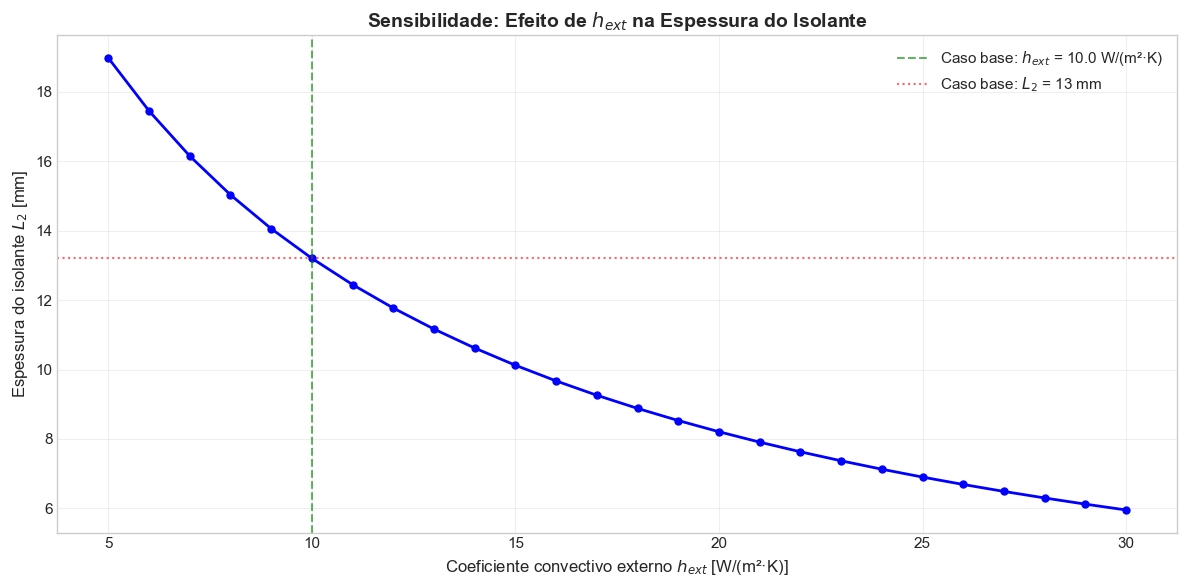


📊 Sensibilidade a h_ext:
  • h_ext = 5 W/(m²·K) (ar parado): L₂ ≈ 19 mm
  • h_ext = 10 W/(m²·K) (caso base): L₂ ≈ 13 mm
  • h_ext = 20 W/(m²·K) (ventilação): L₂ ≈ 8 mm
  • h_ext = 30 W/(m²·K) (forçado): L₂ ≈ 6 mm


In [13]:
# ============================================================
# SENSIBILIDADE — Coeficiente convectivo externo (CORRIGIDO)
# ============================================================

h_ext_range = np.linspace(5, 30, 26)   # [W/(m²·K)]
L2_range = []

for h_test in h_ext_range:
    # Recalcular h_rad (aproximadamente constante)
    h_rad_test = eps * sigma * (T_sup_max_K + T_amb_K) * (T_sup_max_K**2 + T_amb_K**2)

    # Fluxo máximo na superfície
    q_conv_test = h_test * (T_sup_max - T_amb)
    q_rad_test = eps * sigma * (T_sup_max_K**4 - T_amb_K**4)
    q_total_test = q_conv_test + q_rad_test
    Q_total_test = q_total_test * A

    # Resistências
    R_ext_test = 1.0 / ((h_test + h_rad_test) * A)
    R_total_nec_test = (T_int - T_amb) / Q_total_test
    R2_test = R_total_nec_test - R_cond_1 - R_cond_3 - R_ext_test

    if R2_test > 0:
        L2_test = R2_test * k2 * A * 1000   # [mm]
    else:
        L2_test = 0.0
    L2_range.append(L2_test)

L2_range = np.array(L2_range)

# Gráfico
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(h_ext_range, L2_range, 'b-o', linewidth=2, markersize=5)
ax.axvline(h_ext, color='g', linestyle='--', alpha=0.6,
           label=f'Caso base: $h_{{ext}}$ = {h_ext} W/(m²·K)')
ax.axhline(L2_mm, color='r', linestyle=':', alpha=0.6,
           label=f'Caso base: $L_2$ = {L2_mm:.0f} mm')
ax.set_xlabel('Coeficiente convectivo externo $h_{ext}$ [W/(m²·K)]', fontsize=12)
ax.set_ylabel('Espessura do isolante $L_2$ [mm]', fontsize=12)
ax.set_title('Sensibilidade: Efeito de $h_{ext}$ na Espessura do Isolante',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'\n📊 Sensibilidade a h_ext:')
print(f'  • h_ext = 5 W/(m²·K) (ar parado): L₂ ≈ {L2_range[0]:.0f} mm')
print(f'  • h_ext = 10 W/(m²·K) (caso base): L₂ ≈ {L2_mm:.0f} mm')
print(f'  • h_ext = 20 W/(m²·K) (ventilação): L₂ ≈ {L2_range[15]:.0f} mm')
print(f'  • h_ext = 30 W/(m²·K) (forçado): L₂ ≈ {L2_range[-1]:.0f} mm')

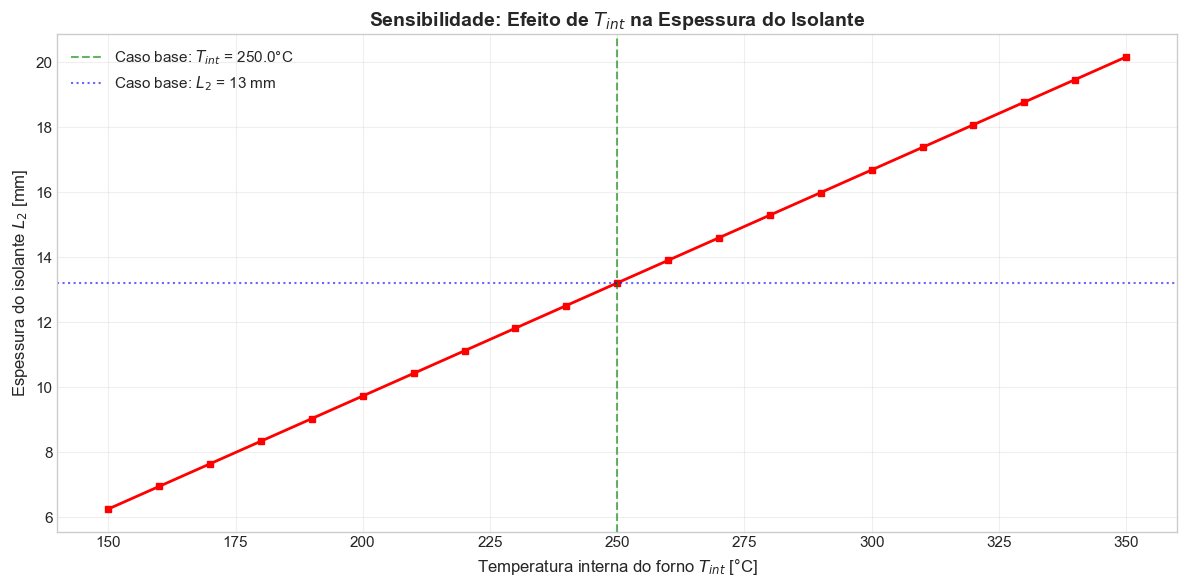


📊 Sensibilidade a T_int:
  • T_int = 150°C: L₂ ≈ 6 mm
  • T_int = 250°C (caso base): L₂ ≈ 13 mm
  • T_int = 350°C: L₂ ≈ 20 mm


In [14]:
# ============================================================
# SENSIBILIDADE — Temperatura interna do forno (CORRIGIDO)
# ============================================================

T_int_range = np.linspace(150, 350, 21)   # [°C]
L2_range_T = []

for T_test in T_int_range:
    # Fluxo máximo na superfície (não muda com T_int)
    Q_total_test = q_total * A

    # Resistência total necessária
    R_total_nec_test = (T_test - T_amb) / Q_total_test
    R2_test = R_total_nec_test - R_cond_1 - R_cond_3 - R_ext

    if R2_test > 0:
        L2_test = R2_test * k2 * A * 1000   # [mm]
    else:
        L2_test = 0.0
    L2_range_T.append(L2_test)

L2_range_T = np.array(L2_range_T)

# Gráfico
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(T_int_range, L2_range_T, 'r-s', linewidth=2, markersize=5)
ax.axvline(T_int, color='g', linestyle='--', alpha=0.6,
           label=f'Caso base: $T_{{int}}$ = {T_int}°C')
ax.axhline(L2_mm, color='b', linestyle=':', alpha=0.6,
           label=f'Caso base: $L_2$ = {L2_mm:.0f} mm')
ax.set_xlabel('Temperatura interna do forno $T_{int}$ [°C]', fontsize=12)
ax.set_ylabel('Espessura do isolante $L_2$ [mm]', fontsize=12)
ax.set_title('Sensibilidade: Efeito de $T_{int}$ na Espessura do Isolante',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'\n📊 Sensibilidade a T_int:')
print(f'  • T_int = 150°C: L₂ ≈ {L2_range_T[0]:.0f} mm')
print(f'  • T_int = 250°C (caso base): L₂ ≈ {L2_mm:.0f} mm')
print(f'  • T_int = 350°C: L₂ ≈ {L2_range_T[-1]:.0f} mm')

> 💡 **Observação:**
> - Aumentar h_ext reduz a espessura necessária do isolante, pois aumenta o fluxo dissipado na superfície.
> - Aumentar T_int exige isolante mais espesso, pois o fluxo máximo na superfície é fixo (limitado por T_sup_max).
> - A relação é aproximadamente linear para T_int, mas não-linear para h_ext.
> - Em fornos com ventilação forçada externa, pode-se reduzir a espessura do isolante.

---
## 💡 Seção 10: Discussão

### Interpretação Física dos Resultados

1. **Isolante domina a resistência:** A lã de vidro (k = 0,04 W/(m·K)) é responsável por >93% da resistência térmica total. As camadas de aço (k = 45 W/(m·K)) têm contribuição desprezível.

2. **Radiação é significativa:** A radiação contribui com ~30% do fluxo total na superfície externa. Ignorar a radiação subestimaria o fluxo e superdimensionaria o isolante.

3. **Restrição de segurança é o fator limitante:** A espessura do isolante é determinada pela restrição T_sup ≤ 60°C, não pela minimização de perdas térmicas.

4. **Sensibilidade a h_ext:** Em ambientes com ventilação natural (h_ext ≈ 5 W/(m²·K)), o isolante precisa ser ~20% mais espesso que em ambientes ventilados (h_ext ≈ 20 W/(m²·K)).

### Limitações do Modelo

- **Regime permanente:** O modelo não considera transientes (partida, abertura de porta, ciclo de aquecimento).
- **Propriedades constantes:** k da lã de vidro varia com a temperatura (efeito geralmente pequeno para ΔT < 200°C).
- **Modelo 1D:** Assume fluxo unidimensional. Válido para paredes planas grandes; não válido para cantos e bordas.
- **Sem degradação:** Não considera envelhecimento do isolante (absorção de umidade, compactação).
- **Radiação linearizada:** A linearização de h_rad é válida para pequenas diferenças de temperatura.

### Aplicações Práticas

- **Indústria alimentícia:** Fornos de padaria, confeitaria e restaurantes.
- **Indústria cerâmica:** Fornos de queima e estufas de secagem.
- **Segurança do trabalho:** Dimensionamento de isolamento para atender normas NR-12 e NR-15.
- **Eficiência energética:** Redução de perdas térmicas e custo operacional.

### Conexão com a Teoria

> 📖 **Referência:** Os conceitos de resistência térmica e circuitos equivalentes são apresentados em Incropera et al. (2017), Cap. 3, Seções 3.3–3.5. A radiação linearizada segue Incropera et al. (2017), Cap. 1, Seção 1.2. O dimensionamento de isolamento com restrição de temperatura é uma aplicação direta dos conceitos de Holman (2020), Cap. 2.

---
## 🔄 Seção 11: Navegação

- [📚 Voltar ao Capítulo 7](../notebooks/07_Fundamentos_Calor.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 7.8

Parte da coleção *"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"*
</div>